# Analyse: findings and charts (before & after)

Input: the raw files (for the "before") and `merged_clean.csv` (for the "after"). This notebook changes no value and writes no file.

Every analysis answers one question and has three parts:
1. **Chart** before and after the cleaning, or on the clean table when the raw data cannot answer.
2. **CHECK** cell with the numbers behind the chart.
3. **Finding**, written in a few lines.

Each analysis says which rows it uses. The filters come from `describe.ipynb`, section 8.

A few functions were not shown in class: `.plot` for the charts, `pd.cut` for the lead time classes, `str.zfill` for the month labels, and `to_dict` to print short results on one line.

## 0. Setup

In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/merged_clean.csv",
                 parse_dates=["arrival_date", "reservation_status_date", "record_updated_at"])
raw_pms = pd.read_excel("../data/raw/hotel_reservations_pms.xlsx", sheet_name="bookings")
raw_crm = pd.read_csv("../data/raw/hotel_bookings_crm.csv", sep=";", dtype=str)

nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
price_ok = (df["adr"] > 0) & (nights > 0) & ~df["adr_outlier"]
no_refund = df["deposit_type"] == "Non Refund"
print("final table:", df.shape, "| rows for price analyses:", price_ok.sum())
print("raw PMS:", raw_pms.shape, "| raw CRM:", raw_crm.shape)

final table: (25000, 68) | rows for price analyses: 23856
raw PMS: (24480, 20) | raw CRM: (24608, 18)


`raw_crm` is read as text (`dtype=str`), as in `crm_cleaning.ipynb`: the raw values must be seen exactly as they are in the file.

## 1. How much does a night cost in each hotel?

**Rows:** before, every raw PMS adr that is a number; after, `price_ok` (price above 0, at least one night, not the outlier).

rows before: 23872 | rows after: 23856
              before (raw PMS)  after (clean)
hotel                                        
City Hotel               118.0          107.0
Resort Hotel             105.4           96.2


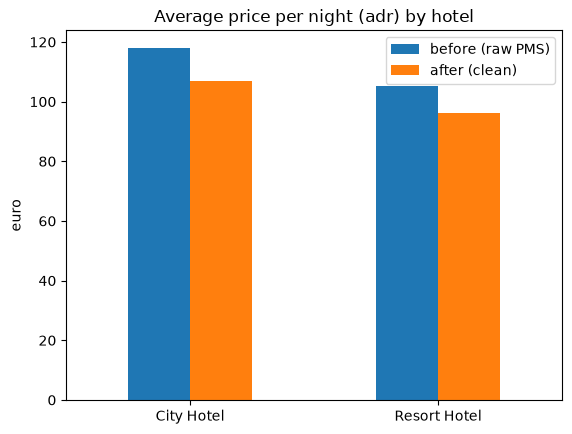

In [2]:
adr_raw = pd.to_numeric(raw_pms["adr"], errors="coerce")
raw_hotel = raw_pms["hotel"].str.strip().str.title()
before = adr_raw.groupby(raw_hotel).mean()
after = df[price_ok].groupby("hotel")["adr"].mean()
adr_hotel = pd.DataFrame({"before (raw PMS)": before, "after (clean)": after}).round(1)
print("rows before:", adr_raw.notna().sum(), "| rows after:", price_ok.sum())
print(adr_hotel)
ax = adr_hotel.plot(kind="bar", rot=0, title="Average price per night (adr) by hotel", xlabel="", ylabel="euro")

In [3]:
# CHECK: where the difference comes from
print("raw adr: min", adr_raw.min(), "| max", adr_raw.max(), "| below 0:", (adr_raw < 0).sum(),
      "| above 1000:", (adr_raw > 1000).sum(), "| equal to 0:", (adr_raw == 0).sum(),
      "| text:", (raw_pms["adr"].notna() & adr_raw.isna()).sum())
print("raw mean:", round(adr_raw.mean(), 1), "| without the values above 1000:", round(adr_raw[adr_raw <= 1000].mean(), 1))
plausible = (adr_raw > 0) & (adr_raw <= 1000)
print("raw, only 0 < adr <= 1000:", adr_raw[plausible].groupby(raw_hotel[plausible]).mean().round(1).to_dict())
print("clean: mean", round(df.loc[price_ok, "adr"].mean(), 1), "| max", df.loc[price_ok, "adr"].max())

raw adr: min -200.0 | max 17910.0 | below 0: 40 | above 1000: 31 | equal to 0: 374 | text: 608
raw mean: 113.8 | without the values above 1000: 101.4
raw, only 0 < adr <= 1000: {'City Hotel': 106.9, 'Resort Hotel': 96.2}
clean: mean 103.4 | max 387.0


**Finding.** The raw file overstates the price: 118.0 euro a night in the City Hotel and 105.4 in the Resort, against 107.0 and 96.2 after the cleaning.
- The error comes almost all from **31 prices above 1,000 euro** (up to 17,910). They are prices multiplied by 100: removing them alone brings the raw mean from 113.8 to 101.4.
- The raw file also has 40 negative prices, 374 prices of 0 and 608 that are text.
- **After the cleaning** the City Hotel costs about 11 euro a night more than the Resort. The mean is 103.4 euro and the maximum 387.

## 2. How many bookings are cancelled?

**Rows:** before, the raw CRM, counting the statuses as written (`Canceled` and `No-Show`); after, all 25,000 bookings (`is_canceled` counts No-Show as cancelled).

cancelled before: 8957 of 24608 | after: 9304 of 25000
              before (raw CRM)  after (clean)
City Hotel                41.2           42.2
Resort Hotel              26.9           27.3


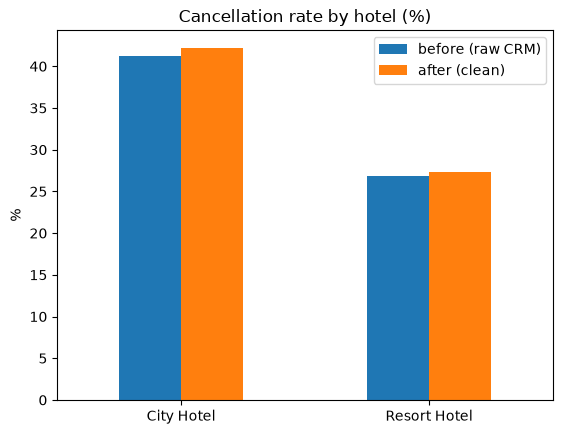

In [4]:
canc_raw = raw_crm["reservation_status"].isin(["Canceled", "No-Show"])
before = canc_raw.groupby(raw_crm["property"].str.strip().str.title()).mean() * 100
after = df.groupby("hotel")["is_canceled"].mean() * 100
cancel_hotel = pd.DataFrame({"before (raw CRM)": before, "after (clean)": after}).round(1)
print("cancelled before:", canc_raw.sum(), "of", len(raw_crm), "| after:", int(df["is_canceled"].sum()), "of", len(df))
print(cancel_hotel)
ax = cancel_hotel.plot(kind="bar", rot=0, title="Cancellation rate by hotel (%)", xlabel="", ylabel="%")

In [5]:
# CHECK: the raw statuses, and the count with every spelling
print(raw_crm["reservation_status"].value_counts())
status = (raw_crm["reservation_status"].str.strip().str.lower()
          .str.replace("cancelled", "canceled").str.replace("no show", "no-show"))
canc_all = status.isin(["canceled", "no-show"])
print("raw CRM, every spelling:", canc_all.sum(), "of", len(raw_crm), round(canc_all.mean() * 100, 1), "%")

reservation_status
Check-Out    14906
Canceled      8708
No-Show        249
CheckOut       167
check-out      160
Check Out      156
canceled        84
CANCELED        81
Cancelled       80
no-show          6
No Show          3
Name: count, dtype: int64
raw CRM, every spelling: 9211 of 24608 37.4 %


**Finding.** More than one booking in three is cancelled: **42.2% in the City Hotel and 27.3% in the Resort**.
- Counting the raw file as it is gives 8,957 cancellations. This misses 254 written in other ways (`canceled`, `CANCELED`, `Cancelled`, `No Show`…): with every spelling there are 9,211 (37.4%).
- The cleaning also adds the 500 PMS-only bookings and corrects 50 `Canceled` statuses that were really check-outs. The final count is 9,304 of 25,000.

## 3. The deposit type explains a large share of the cancellations

Before the other analyses: one group of bookings is cancelled almost always, and it changes several results below. This analysis does not compare before and after: it uses the clean table to explain the next ones.

               size  mean
deposit_type             
No Deposit    21293  28.8
Non Refund     2924  99.5
Refundable       33   9.1


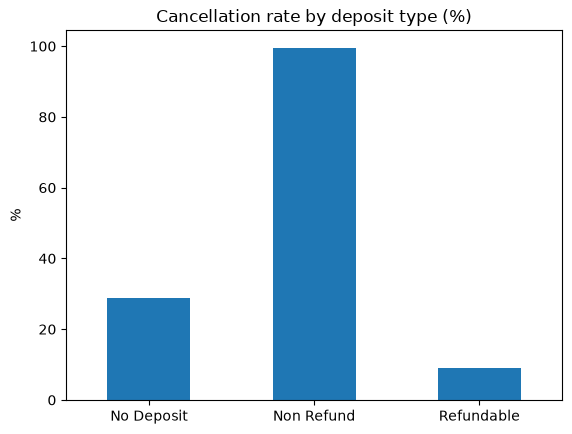

In [6]:
dep = df.groupby("deposit_type")["is_canceled"].agg(["size", "mean"])
dep["mean"] = (dep["mean"] * 100).round(1)
print(dep)
ax = dep["mean"].plot(kind="bar", rot=0, title="Cancellation rate by deposit type (%)", xlabel="", ylabel="%")

In [7]:
# CHECK: where the Non Refund bookings are
print(df.loc[no_refund, "market_segment"].value_counts().head(3))
print(df.loc[no_refund, "hotel"].value_counts())

market_segment
Groups           1810
Offline TA/TO     978
Corporate          65
Name: count, dtype: int64
hotel
City Hotel      2584
Resort Hotel     340
Name: count, dtype: int64


**Finding.** The **2,924 `Non Refund` bookings are cancelled in 99.5% of cases**, against 28.8% for `No Deposit`.
- They are almost all in the City Hotel (2,584) and in two segments: Groups (1,810) and Offline TA/TO (978).
- A non-refundable booking that is almost always cancelled is surprising. The data show it, but cannot tell why, for example how the hotel uses this label. We report it as it is.
- **Consequence:** wherever these bookings are concentrated, the cancellation rate goes up. So in the next analyses we show every rate **with and without `Non Refund`**.

## 4. Are bookings made further ahead cancelled more?

**Rows:** bookings with a known lead time. Before, the raw CRM (text read as numbers); after, the clean table.

lead times before:

 23618 | of which 9999: 25 | after: 24475
              before (raw CRM)  after (clean)
Canceled                 155.8          143.4
Not canceled              90.5           80.2


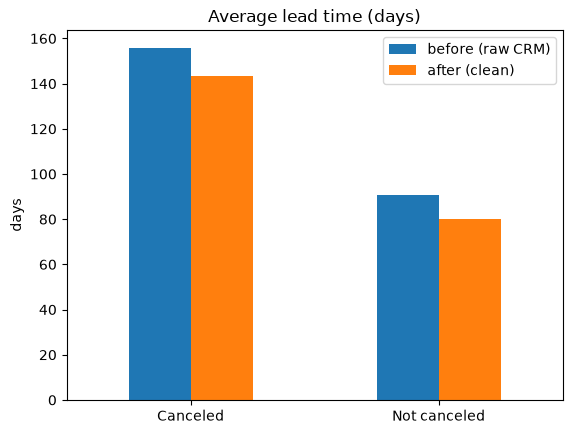

In [8]:
lead_raw = pd.to_numeric(raw_crm["lead_time_days"], errors="coerce")
before = lead_raw.groupby(canc_raw.map({True: "Canceled", False: "Not canceled"})).mean()
after = df.groupby(df["is_canceled"].map({1: "Canceled", 0: "Not canceled"}))["lead_time_days"].mean()
lead_mean = pd.DataFrame({"before (raw CRM)": before, "after (clean)": after}).round(1)
print("lead times before:", lead_raw.notna().sum(), "| of which 9999:", (lead_raw == 9999).sum(),
      "| after:", df["lead_time_days"].notna().sum())
print(lead_mean)
ax = lead_mean.plot(kind="bar", rot=0, title="Average lead time (days)", xlabel="", ylabel="days")

In [9]:
# CHECK: the effect of the 9999 code
known = lead_raw != 9999
print("raw mean:", round(lead_raw.mean(), 1), "| without 9999:", round(lead_raw[known].mean(), 1),
      "| clean:", round(df["lead_time_days"].mean(), 1))
print("raw without 9999:", lead_raw[known].groupby(canc_raw[known].map({True: "Canceled", False: "Not canceled"})).mean().round(1).to_dict())
print("median after:", df.groupby("is_canceled")["lead_time_days"].median().to_dict())

raw mean: 114.2 | without 9999: 103.7 | clean: 103.7
raw without 9999: {'Canceled': 143.1, 'Not canceled': 81.2}
median after: {0.0: 46.0, 1.0: 113.0}


                size  mean  without Non Refund
lead_time_days                                
0-7             3970   9.9                 9.5
8-30            3876  27.4                25.9
31-90           6133  38.0                33.0
91-180          5500  45.3                35.6
181-365         4363  55.2                40.4
366+             633  67.6                20.5


366+ bookings: 633 | of which Non Refund: 375


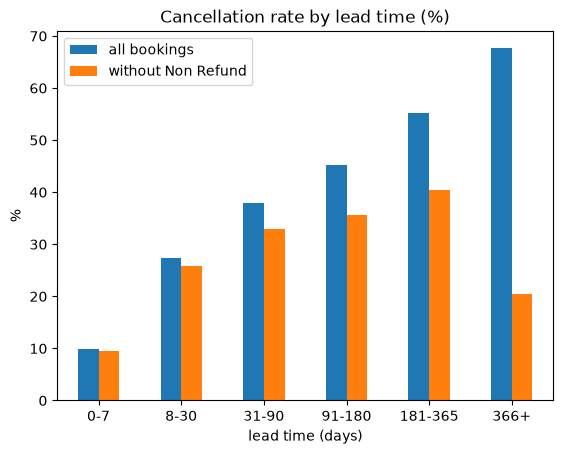

In [10]:
classes = pd.cut(df["lead_time_days"], bins=[-1, 7, 30, 90, 180, 365, 800],
                 labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"])
rate = df.groupby(classes, observed=True)["is_canceled"].agg(["size", "mean"])
rate["mean"] = (rate["mean"] * 100).round(1)
rate["without Non Refund"] = (df[~no_refund].groupby(classes[~no_refund], observed=True)["is_canceled"].mean() * 100).round(1)
print(rate)
print("366+ bookings:", (classes == "366+").sum(), "| of which Non Refund:", ((classes == "366+") & no_refund).sum())
ax = rate[["mean", "without Non Refund"]].rename(columns={"mean": "all bookings"}).plot(kind="bar", rot=0, title="Cancellation rate by lead time (%)",
                                               xlabel="lead time (days)", ylabel="%")

**Finding.** Yes: **the further ahead a booking is made, the more often it is cancelled.**
- Cancelled bookings were made 143 days ahead on average, the others 80. The medians are 113 and 46 days.
- In the raw file the means are higher (155.8 and 90.5), because 25 lead times are the code `9999` ("unknown"). Without them the raw mean is 103.7, the same as the clean one.
- By class, the rate goes from 9.9% (0-7 days) to 67.6% (more than a year).
- **But the last class is mostly `Non Refund`** (375 of 633 bookings). Without them it falls to 20.5%. Without `Non Refund` the rate still rises from 9.5% to 40.4% up to one year ahead. The real effect is there, but it is smaller than the raw chart suggests.

## 5. Which market segments cancel the most?

**Before:** how the raw CRM writes the segment. **After:** cancellation rate by segment on the clean table.

spellings before: 22 | segments after: 7
market_segment
Online TA        11592
Offline TA/TO     4846
Groups            4040
Direct            2484
Corporate         1080
Complementary      140
Online T.A.         81
Onlne TA            57
online ta           49
Aviation            47
Offline TA-TO       31
Ofline TA/TO        24
offline ta/to       24
Groups              23
Direct              18
Group               15
direct              15
groups              13
Corporte             9
corporate            7
complementary        3
Undefined            2
Name: count, dtype: int64


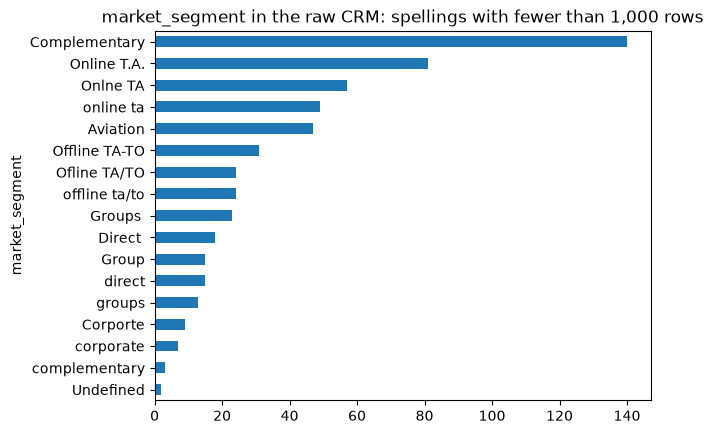

In [11]:
before = raw_crm["market_segment"].value_counts()
after = df["market_segment"].value_counts()
print("spellings before:", before.size, "| segments after:", after.size)
print(before)
ax = before[before < 1000].sort_values().plot(kind="barh", title="market_segment in the raw CRM: spellings with fewer than 1,000 rows")

                 size  mean  Non Refund  without Non Refund
market_segment                                             
Complementary     142  11.3         NaN                11.3
Direct           2504  14.4         3.0                14.3
Corporate        1090  18.3        65.0                13.8
Aviation           47  23.4         NaN                23.4
Offline TA/TO    4907  34.2       978.0                17.8
Online TA       11737  37.1        11.0                37.1
Groups           4071  61.4      1810.0                30.8


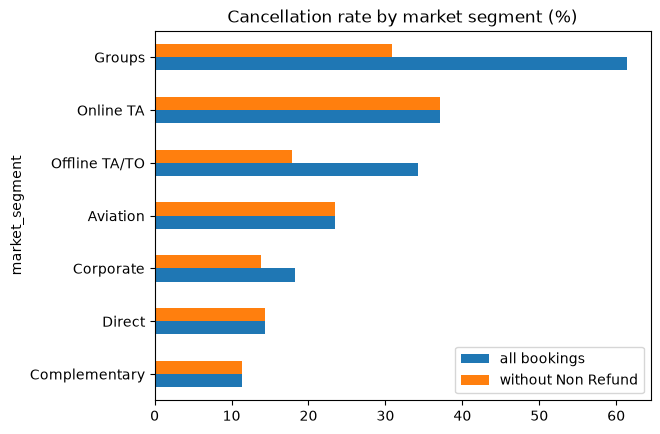

In [12]:
seg = df.groupby("market_segment")["is_canceled"].agg(["size", "mean"])
seg["mean"] = (seg["mean"] * 100).round(1)
seg["Non Refund"] = df[no_refund].groupby("market_segment").size()
seg["without Non Refund"] = (df[~no_refund].groupby("market_segment")["is_canceled"].mean() * 100).round(1)
print(seg.sort_values("mean"))
ax = seg[["mean", "without Non Refund"]].sort_values("mean").rename(columns={"mean": "all bookings"}).plot(kind="barh", title="Cancellation rate by market segment (%)")

**Finding.**
- **Before:** the raw CRM writes 7 segments in 22 ways (`Online T.A.`, `Onlne TA`, `online ta`, `Corporte`…). Any count by segment on the raw file splits the same segment into several rows.
- **After:** Groups cancel the most (61.4%), then Online TA (37.1%) and Offline TA/TO (34.2%).
- **Without `Non Refund` the ranking changes.** Groups fall to 30.8% and Offline TA/TO to 17.8%, because they hold 1,810 and 978 of those bookings. Online TA stays at 37.1% and becomes the segment that cancels the most.
- Direct (14.3%) and Corporate (13.8%) are the most reliable.

## 6. How do bookings and cancellations change over time?

**Rows:** all 25,000 bookings, by month of arrival (`arrival_date` is complete). This analysis uses only the clean table: the raw CRM writes the check-in date in three formats, and the 750 CRM-only bookings have no PMS date.

months: 26 | bookings: fewest 2016-01 454 | most 2016-10 1346
cancellation %: lowest 2016-01 21.1 | highest 2015-07 45.0
peak month: {'City Hotel': '2017-05', 'Resort Hotel': '2016-10'} | bookings: {'City Hotel': 908, 'Resort Hotel': 446}


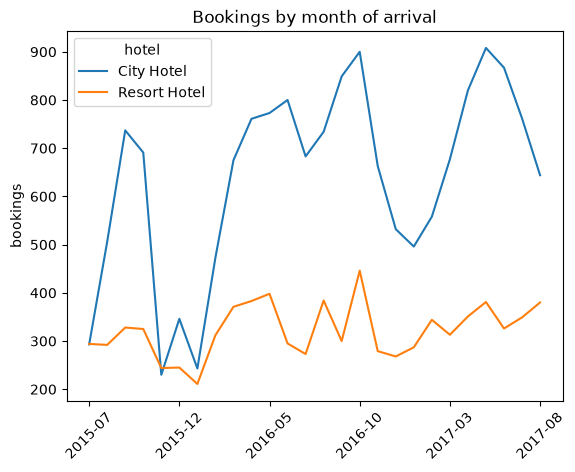

In [13]:
month = df["arrival_date"].dt.year.astype(str) + "-" + df["arrival_date"].dt.month.astype(str).str.zfill(2)
monthly = df.groupby(month)["is_canceled"].agg(["size", "mean"])
monthly["mean"] = (monthly["mean"] * 100).round(1)
print("months:", len(monthly), "| bookings: fewest", monthly["size"].idxmin(), monthly["size"].min(),
      "| most", monthly["size"].idxmax(), monthly["size"].max())
print("cancellation %: lowest", monthly["mean"].idxmin(), monthly["mean"].min(),
      "| highest", monthly["mean"].idxmax(), monthly["mean"].max())
by_hotel = df.groupby([month, "hotel"]).size().unstack()
print("peak month:", by_hotel.idxmax().to_dict(), "| bookings:", by_hotel.max().to_dict())
ax = by_hotel.plot(title="Bookings by month of arrival", rot=45, xlabel="", ylabel="bookings")

In [14]:
# CHECK: 2016 against 2017 on the same months (January to August)
jan_aug = df[(df["arrival_date"].dt.month <= 8) & (df["arrival_date"].dt.year >= 2016)]
year = jan_aug["arrival_date"].dt.year
print(jan_aug.groupby(year).size())
print((jan_aug.groupby(year)["is_canceled"].mean() * 100).round(1))
print((jan_aug.groupby([year, "hotel"])["is_canceled"].mean() * 100).round(1).unstack())

arrival_date
2016    7769
2017    8463
dtype: int64
arrival_date
2016    35.0
2017    38.6
Name: is_canceled, dtype: float64
hotel         City Hotel  Resort Hotel
arrival_date                          
2016                39.2          26.6
2017                42.5          30.5


**Finding.**
- The data cover **26 months**, from July 2015 to August 2017.
- The two hotels peak at different times: the **City Hotel in May 2017** (908 arrivals) and the **Resort Hotel in October 2016** (446).
- The years are partial, so we compare the same months. **From January to August, bookings grow** from 7,769 in 2016 to 8,463 in 2017. **Cancellations grow too**, from 35.0% to 38.6%, and they rise in both hotels: City from 39.2% to 42.5%, Resort from 26.6% to 30.5%.

## 7. Do guests with special requests cancel less?

**Rows:** bookings in the PMS (24,250), the only file with special requests.

                            size  mean  without Non Refund
total_of_special_requests                                 
0                          14287  48.0                34.7
1                           6688  22.2                22.2
2                           2668  22.7                22.7
3                            529  17.0                17.0
4                             70  10.0                10.0
5                              8   0.0                 0.0
Non Refund bookings: 2924 | of which with 0 requests: 2920


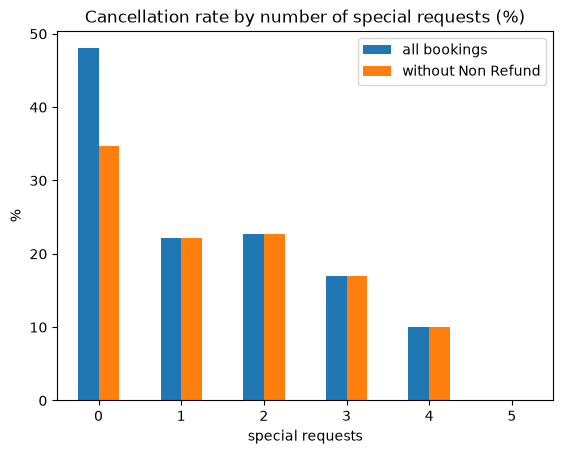

In [15]:
pms_rows = df[df["in_pms"]]
requests = pms_rows["total_of_special_requests"].astype(int)
req = pms_rows.groupby(requests)["is_canceled"].agg(["size", "mean"])
req["mean"] = (req["mean"] * 100).round(1)
nr = pms_rows["deposit_type"] == "Non Refund"
req["without Non Refund"] = (pms_rows[~nr].groupby(requests[~nr])["is_canceled"].mean() * 100).round(1)
print(req)
print("Non Refund bookings:", nr.sum(), "| of which with 0 requests:", (nr & (requests == 0)).sum())
ax = req[["mean", "without Non Refund"]].rename(columns={"mean": "all bookings"}).plot(kind="bar", rot=0, title="Cancellation rate by number of special requests (%)",
                                              xlabel="special requests", ylabel="%")

**Finding.** Yes: **guests who ask for something cancel less.**
- With no requests, 48.0% of bookings are cancelled; with 1 or 2 requests, about 22%; with 3, 17.0%; with 4, 10.0%. The 8 bookings with 5 requests are too few to count.
- **Part of the gap is `Non Refund` again:** 2,920 of those 2,924 bookings have no requests. Without them, bookings with no requests cancel 34.7%, still well above those with requests.

## 8. Summary

| # | Question | Finding |
|---|---|---|
| 1 | Price per night | Raw prices overstated by 31 values multiplied by 100. Clean: City 107.0, Resort 96.2 euro |
| 2 | Cancellations | 254 cancellations hidden by spelling. Clean: City 42.2%, Resort 27.3% |
| 3 | Deposit type | `Non Refund` (2,924 bookings) is cancelled in 99.5% of cases, and inflates the rates of the groups where it is concentrated |
| 4 | Lead time | The further ahead, the more cancellations: from 9.5% to 40.4% without `Non Refund` |
| 5 | Segments | 22 spellings for 7 segments. Without `Non Refund`, Online TA cancels the most (37.1%), not Groups |
| 6 | Over time | City peak May 2017, Resort October 2016; January-August cancellations from 35.0% to 38.6% |
| 7 | Special requests | No requests 48.0% (34.7% without `Non Refund`), 1-2 requests about 22% |

**What the cleaning changed in the conclusions:** the price per night, the cancellation counts and the lead time were wrong on the raw files. The `Non Refund` check changes which segment looks riskiest.